# Лабораторная работа 1. Моделирование и исследование случайных процессов

Курс «Модели случайных процессов и анализ временных рядов».

Исследуются винеровский процесс $W_t$, пуассоновский процесс $N_t$ интенсивности $\lambda$ и процесс Орнштейна–Уленбека (ОУ) $X_t$ на сетке $t_k = k\Delta$, $k = 0, \dots, n$, $n = T/\Delta$. Все траектории строятся самостоятельно из приращений (винеровский и пуассоновский процессы) или из точного переходного закона (ОУ). Из библиотек используются только генераторы нормальных и пуассоновских величин, операции над массивами, статистики и графики.

Порядок работы: 1 — параметры экспериментов; 2 — функции моделирования и их проверка; 3 — ансамблевые характеристики; 4 — приращения; 5 — процесс ОУ; 6 — итоговые выводы; 7 — вклад участников.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

## 1. Параметры экспериментов

Базовый набор: горизонт $T$, шаг $\Delta$, число траекторий $M$ и seed. Параметры процессов задаются отдельно и передаются в функции моделирования как аргументы, поэтому любую величину можно менять независимо. Для каждого эксперимента генератор создаётся как `np.random.default_rng([SEED, ...])` с собственным ключом, так что результаты отдельных блоков не зависят от порядка их выполнения.

Для ОУ стационарная дисперсия равна $\sigma^2/(2\theta)$, время релаксации — $1/\theta$. Фиксированное начальное значение $x_0 = -3$ отстоит от $\mu = 1$ на четыре стационарных стандартных отклонения при $\theta = 0.5$, чтобы переходный режим был хорошо заметен.

In [2]:
SEED = 2026
BASE = dict(T=10.0, dt=0.01, M=2000)
LAM = 2.0
OU = dict(theta=1.0, mu=1.0, sigma=1.0, x0=-3.0)
COV_TIMES = np.array([0.5, 1.0, 2.0, 4.0, 6.0, 9.0])
M_GRID = [50, 100, 200, 500, 1000, 2000, 5000]
N_REP = 20

pd.DataFrame(
    [
        ("T", BASE["T"], "горизонт"),
        ("Δ", BASE["dt"], "шаг сетки"),
        ("n = T/Δ", int(round(BASE["T"] / BASE["dt"])), "число шагов"),
        ("M", BASE["M"], "число траекторий"),
        ("seed", SEED, "базовый seed"),
        ("λ", LAM, "интенсивность пуассоновского процесса"),
        ("θ, μ, σ", f"{OU['theta']}, {OU['mu']}, {OU['sigma']}", "параметры ОУ"),
        ("x0", OU["x0"], "фиксированное начальное состояние ОУ"),
        ("t1, ..., tm", list(COV_TIMES), "моменты для ковариационной матрицы"),
        ("M для ошибок", M_GRID, f"по {N_REP} повторений"),
    ],
    columns=["параметр", "значение", "смысл"],
)

,параметр,значение,смысл
0,T,10.0,горизонт
1,Δ,0.01,шаг сетки
2,n = T/Δ,1000,число шагов
3,M,2000,число траекторий
4,seed,2026,базовый seed
5,λ,2.0,интенсивность пуассоновского процесса
6,"θ, μ, σ","1.0, 1.0, 1.0",параметры ОУ
7,x0,-3.0,фиксированное начальное состояние ОУ
8,"t1, ..., tm","[0.5, 1.0, 2.0, 4.0, 6.0, 9.0]",моменты для ковариационной матрицы
9,M для ошибок,"[50, 100, 200, 500, 1000, 2000, 5000]",по 20 повторений


## 2. Функции моделирования

Каждая функция принимает параметры сетки $(T, \Delta)$, число траекторий $M$, параметры процесса и генератор `rng`, а возвращает сетку `t` длины $n+1$ и ансамбль формы $(M, n+1)$: строка — траектория, столбец — момент времени.

* Винеровский процесс: $W_0 = 0$, $W_{t_{k+1}} = W_{t_k} + \xi_{k+1}$, $\xi_k \sim \mathcal N(0, \Delta)$ независимы; траектория — кумулятивная сумма приращений.
* Пуассоновский процесс: $N_0 = 0$, приращения $\sim \mathrm{Pois}(\lambda\Delta)$ независимы.
* ОУ: точный переход $X_{t_{k+1}} - \mu = e^{-\theta\Delta}(X_{t_k} - \mu) + \eta_{k+1}$, $\eta_k \sim \mathcal N\big(0, \tfrac{\sigma^2}{2\theta}(1 - e^{-2\theta\Delta})\big)$; начальное состояние либо $x_0$, либо (при `x0=None`) $\mathcal N(\mu, \sigma^2/(2\theta))$. Схема точная, поэтому ошибки дискретизации нет при любом $\Delta$.

Рядом определены теоретические функции среднего и ковариации. Для ОУ с фиксированным $x_0$
$$\mathbb E X_t = \mu + (x_0 - \mu)e^{-\theta t}, \qquad \mathrm{Cov}(X_s, X_t) = \frac{\sigma^2}{2\theta}\left(e^{-\theta|t-s|} - e^{-\theta(t+s)}\right),$$
для стационарного начала второе слагаемое пропадает и $\mathbb E X_t = \mu$.

In [3]:
def time_grid(T, dt):
    n = int(round(T / dt))
    if n < 1 or not np.isclose(n * dt, T):
        raise ValueError("T должно быть кратно dt")
    return np.arange(n + 1) * dt


def simulate_wiener(T, dt, M, rng):
    t = time_grid(T, dt)
    dW = rng.normal(0.0, np.sqrt(dt), size=(M, t.size - 1))
    W = np.zeros((M, t.size))
    np.cumsum(dW, axis=1, out=W[:, 1:])
    return t, W


def simulate_poisson(T, dt, M, lam, rng):
    t = time_grid(T, dt)
    dN = rng.poisson(lam * dt, size=(M, t.size - 1))
    N = np.zeros((M, t.size), dtype=np.int64)
    np.cumsum(dN, axis=1, out=N[:, 1:])
    return t, N


def simulate_ou(T, dt, M, theta, mu, sigma, rng, x0=None):
    t = time_grid(T, dt)
    a = np.exp(-theta * dt)
    s = np.sqrt(sigma**2 / (2 * theta) * (1 - a**2))
    X = np.empty((M, t.size))
    X[:, 0] = rng.normal(mu, sigma / np.sqrt(2 * theta), size=M) if x0 is None else x0
    eta = rng.normal(0.0, s, size=(M, t.size - 1))
    for k in range(t.size - 1):
        X[:, k + 1] = mu + a * (X[:, k] - mu) + eta[:, k]
    return t, X


def ou_mean(t, theta, mu, x0):
    t = np.asarray(t, dtype=float)
    return np.full_like(t, mu) if x0 is None else mu + (x0 - mu) * np.exp(-theta * t)


def ou_cov(s, t, theta, sigma, x0):
    d = sigma**2 / (2 * theta)
    K = d * np.exp(-theta * np.abs(np.subtract.outer(s, t)))
    return K if x0 is None else K - d * np.exp(-theta * np.add.outer(s, t))


def make_processes(lam, ou):
    th, mu, sg, x0 = ou["theta"], ou["mu"], ou["sigma"], ou["x0"]
    return {
        "Винер": dict(
            sim=lambda T, dt, M, rng: simulate_wiener(T, dt, M, rng),
            mean=lambda t: np.zeros_like(t),
            cov=lambda s, t: np.minimum.outer(s, t),
        ),
        "Пуассон": dict(
            sim=lambda T, dt, M, rng: simulate_poisson(T, dt, M, lam, rng),
            mean=lambda t: lam * t,
            cov=lambda s, t: lam * np.minimum.outer(s, t),
        ),
        "ОУ, X0 = x0": dict(
            sim=lambda T, dt, M, rng: simulate_ou(T, dt, M, th, mu, sg, rng, x0),
            mean=lambda t: ou_mean(t, th, mu, x0),
            cov=lambda s, t: ou_cov(s, t, th, sg, x0),
        ),
        "ОУ, стац.": dict(
            sim=lambda T, dt, M, rng: simulate_ou(T, dt, M, th, mu, sg, rng, None),
            mean=lambda t: ou_mean(t, th, mu, None),
            cov=lambda s, t: ou_cov(s, t, th, sg, None),
        ),
    }


def theory_var(p, t):
    return np.diag(p["cov"](t, t)).copy()


PROC = make_processes(LAM, OU)
COLORS = dict(zip(PROC, ["C0", "C3", "C2", "C1"]))

### 2.1 Проверка функций

**Вопрос.** Правильные ли размерности и начальные значения у ансамблей и воспроизводится ли результат при фиксированном seed?

Каждый процесс моделируется трижды: дважды с одним seed и один раз с другим. Для стационарного ОУ начальное значение случайно, поэтому вместо точного совпадения сравниваются выборочные среднее и стандартное отклонение $X_0$ с $\mu$ и $\sigma/\sqrt{2\theta}$.

In [4]:
def rng_for(*key):
    return np.random.default_rng([SEED, *key])


T, dt, M = BASE["T"], BASE["dt"], BASE["M"]
ENS = {}
rows = []
for i, (name, p) in enumerate(PROC.items()):
    t, X = p["sim"](T, dt, M, rng_for(1, i))
    _, X_same = p["sim"](T, dt, M, rng_for(1, i))
    _, X_other = p["sim"](T, dt, M, rng_for(2, i))
    ENS[name] = (t, X)
    assert t.shape == (int(round(T / dt)) + 1,) and X.shape == (M, t.size)
    assert np.isclose(t[0], 0) and np.isclose(t[-1], T)
    if name != "ОУ, стац.":
        assert np.all(X[:, 0] == p["mean"](t[:1])[0])
    rows.append(
        {
            "процесс": name,
            "форма ансамбля": X.shape,
            "t[0], t[-1]": (t[0], t[-1]),
            "среднее X0": X[:, 0].mean(),
            "ст. откл. X0": X[:, 0].std(ddof=1),
            "теор. ст. откл. X0": np.sqrt(theory_var(p, t[:1])[0]),
            "тот же seed": np.array_equal(X, X_same),
            "другой seed отличается": not np.array_equal(X, X_other),
        }
    )
pd.DataFrame(rows).set_index("процесс")

,форма ансамбля,"t[0], t[-1]",среднее X0,ст. откл. X0,теор. ст. откл. X0,тот же seed,другой seed отличается
процесс,,,,,,,
Винер,"(2000, 1001)","(0.0, 10.0)",0.0000,0.0000,0.0000,True,True
Пуассон,"(2000, 1001)","(0.0, 10.0)",0.0000,0.0000,0.0000,True,True
"ОУ, X0 = x0","(2000, 1001)","(0.0, 10.0)",-3.0000,0.0000,0.0000,True,True
"ОУ, стац.","(2000, 1001)","(0.0, 10.0)",1.0012,0.7238,0.7071,True,True


**Результат.** Все ансамбли имеют форму $(M, n+1) = (2000, 1001)$, сетка начинается в 0 и заканчивается в $T = 10$. У винеровского и пуассоновского процессов все траектории стартуют из 0, у ОУ с фиксированным началом — из $x_0 = -3$ (разброс $X_0$ нулевой). У стационарного ОУ выборочные среднее и стандартное отклонение $X_0$ равны 1.001 и 0.724 при теоретических $\mu = 1$ и $1/\sqrt2 \approx 0.707$. Повторный запуск с тем же seed даёт тот же массив поэлементно, другой seed — другой массив.

### 2.2 Несколько реализаций

**Вопрос.** Чем качественно различаются траектории процессов?

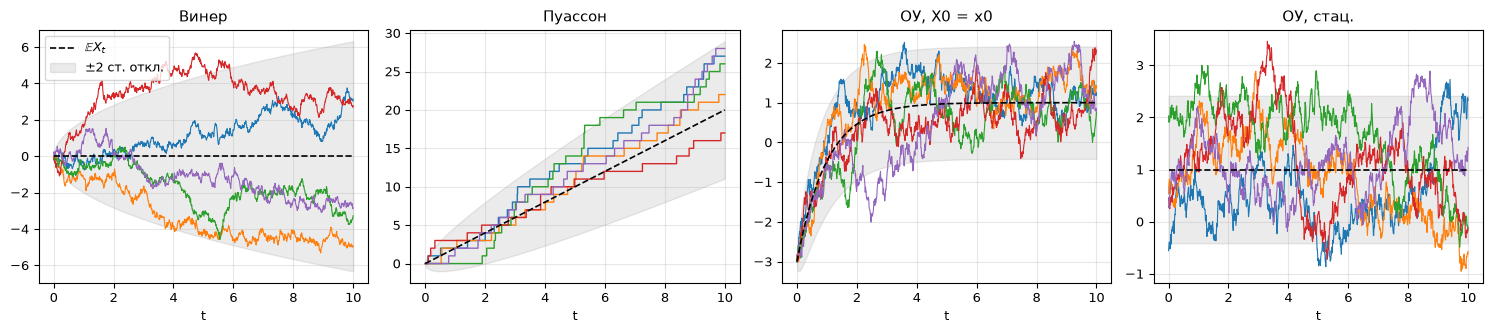

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharex=True)
for ax, (name, (t, X)) in zip(axes, ENS.items()):
    p = PROC[name]
    if name == "Пуассон":
        for j in range(5):
            ax.step(t, X[j], where="post", lw=1)
    else:
        ax.plot(t, X[:5].T, lw=0.8)
    sd = np.sqrt(theory_var(p, t))
    ax.plot(t, p["mean"](t), "k--", lw=1.2, label="$\\mathbb{E}X_t$")
    ax.fill_between(t, p["mean"](t) - 2 * sd, p["mean"](t) + 2 * sd, color="k", alpha=0.08, label="$\\pm 2$ ст. откл.")
    ax.set_title(name)
    ax.set_xlabel("t")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

**Интерпретация.**

* **Винеровский процесс**: непрерывные, сильно изрезанные траектории без тренда. Разброс между траекториями растёт как $\sqrt t$, и каждая траектория может надолго уходить от нуля: к $t = 10$ одна реализация около $+3$, другая около $-5$. Возврата к среднему нет.
* **Пуассоновский процесс**: неубывающие ступенчатые траектории со скачками высоты 1 в случайные моменты. Траектории идут вдоль прямой $\lambda t$ и к $t = 10$ лежат в диапазоне примерно 17–28 при $\mathbb E N_{10} = 20$; разброс растёт как $\sqrt{\lambda t}$.
* **ОУ с $X_0 = -3$**: все траектории стартуют из одной точки и за время порядка нескольких $1/\theta = 1$ подтягиваются к уровню $\mu = 1$. Дальше они колеблются в полосе $\mu \pm 2\sigma/\sqrt{2\theta} \approx [-0.4;\ 2.4]$ и постоянно возвращаются к среднему.
* **Стационарный ОУ**: траектории сразу находятся в той же полосе, никакого переходного участка нет, распределение $X_t$ одно и то же при всех $t$.

Итак, у $W$ и $N$ дисперсия неограниченно растёт и процессы нестационарны, а у ОУ она ограничена: возвращающий снос $-\theta(X_t - \mu)$ удерживает процесс около $\mu$.

## 3. Ансамблевые характеристики

### 3.1 Среднее и дисперсия

**Вопрос.** Совпадают ли ансамблевые оценки $\hat m(t) = \frac1M\sum_j X^{(j)}_t$ и $\hat v(t) = \frac{1}{M-1}\sum_j (X^{(j)}_t - \hat m(t))^2$ с теоретическими функциями?

Теория: $\mathbb E W_t = 0$, $\mathrm D W_t = t$; $\mathbb E N_t = \mathrm D N_t = \lambda t$; для ОУ — формулы из раздела 2. Численные характеристики: максимум $|\hat m - m|$ по сетке, тот же максимум в единицах стандартной ошибки $\sqrt{v(t)/M}$, медиана и максимум относительной ошибки дисперсии $|\hat v/v - 1|$ при $t \ge 0.5$ (около нуля дисперсия у трёх процессов мала и относительная ошибка неинформативна). Для гауссовских процессов стандартное отклонение $\hat v/v$ равно $\sqrt{2/(M-1)} \approx 0.032$.

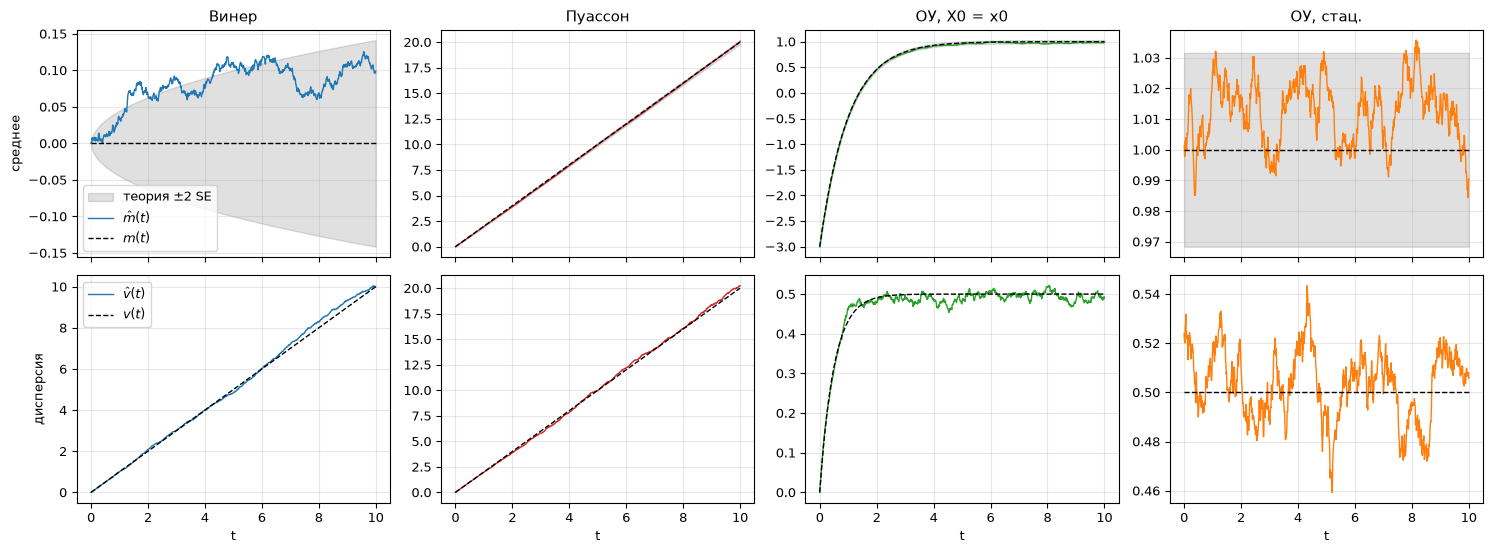

,max |m̂ − m|,max |m̂ − m| / SE,медиана |v̂/v − 1|,max |v̂/v − 1|,v̂(T),v(T)
процесс,,,,,,
Винер,0.1257,2.9097,0.0176,0.0546,9.9879,10.0
Пуассон,0.1120,2.4099,0.0153,0.0474,20.2349,20.0
"ОУ, X0 = x0",0.0474,3.1965,0.0173,0.0924,0.4926,0.5
"ОУ, стац.",0.0358,2.2637,0.0206,0.0867,0.5057,0.5


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6), sharex=True)
rows = []
for c, (name, (t, X)) in enumerate(ENS.items()):
    p = PROC[name]
    m, v = p["mean"](t), theory_var(p, t)
    m_hat, v_hat = X.mean(axis=0), X.var(axis=0, ddof=1)
    se = np.sqrt(v / M)
    axes[0, c].fill_between(t, m - 2 * se, m + 2 * se, color="k", alpha=0.12, label="теория $\\pm 2$ SE")
    axes[0, c].plot(t, m_hat, color=COLORS[name], lw=1, label="$\\hat m(t)$")
    axes[0, c].plot(t, m, "k--", lw=1, label="$m(t)$")
    axes[1, c].plot(t, v_hat, color=COLORS[name], lw=1, label="$\\hat v(t)$")
    axes[1, c].plot(t, v, "k--", lw=1, label="$v(t)$")
    axes[0, c].set_title(name)
    axes[1, c].set_xlabel("t")
    pos, late = v > 0, t >= 0.5
    rel = np.abs(v_hat[late] / v[late] - 1)
    rows.append(
        {
            "процесс": name,
            "max |m̂ − m|": np.abs(m_hat - m).max(),
            "max |m̂ − m| / SE": (np.abs(m_hat - m)[pos] / se[pos]).max(),
            "медиана |v̂/v − 1|": np.median(rel),
            "max |v̂/v − 1|": rel.max(),
            "v̂(T)": v_hat[-1],
            "v(T)": v[-1],
        }
    )
axes[0, 0].set_ylabel("среднее")
axes[1, 0].set_ylabel("дисперсия")
axes[0, 0].legend(loc="lower left")
axes[1, 0].legend(loc="upper left")
fig.tight_layout()
plt.show()
MV_TABLE = pd.DataFrame(rows).set_index("процесс")
MV_TABLE

**Интерпретация.** Ансамблевые оценки повторяют теоретические кривые для всех четырёх процессов: эмпирическое среднее почти везде лежит в полосе $\pm 2$ стандартные ошибки, дисперсия идёт вдоль $t$, $\lambda t$ и функций ОУ. В конце горизонта $\hat v(10) = 9.99$ (теория 10) у $W$, 20.23 (20) у $N$, 0.49 и 0.51 (0.5) у ОУ.

Численно максимальное отклонение среднего составляет 2.3–3.2 стандартной ошибки. Для максимума по тысяче моментов это нормальная величина, систематического сдвига нет. Медианная относительная ошибка дисперсии 1.5–2%, что согласуется со стандартным отклонением $\sqrt{2/(M-1)} \approx 3.2\%$: медиана $|\mathcal N(0, 0.032^2)|$ равна 2.2%. Максимум у ОУ больше (9% против 5% у $W$ и $N$). У $W$ и $N$ ошибки в соседние моменты почти одинаковы, потому что значения процесса накапливают одни и те же приращения. Ошибки ОУ быстро декоррелируют по $t$, и максимум берётся по большему числу почти независимых величин.

Начальное состояние ОУ сказывается только на теоретических функциях: при $X_0 = x_0$ среднее и дисперсия выходят на стационарные значения за время порядка $1/\theta$. На точность ансамблевых оценок в каждый момент оно не влияет.

### 3.2 Ковариационная матрица

**Вопрос.** Насколько ансамблевая оценка $\hat K$ ковариационной матрицы вектора $(X_{t_1}, \dots, X_{t_m})$ близка к теоретической $K$?

Моменты $t_i = 0.5, 1, 2, 4, 6, 9$. Каждая траектория даёт одну реализацию вектора, $\hat K = \frac{1}{M-1}\sum_\ell (\mathbf X^{(\ell)} - \bar{\mathbf X})(\mathbf X^{(\ell)} - \bar{\mathbf X})^\top$. В строке тепловых карт $K$ и $\hat K$ имеют общую шкалу, разность $\hat K - K$ — симметричную шкалу вокруг нуля. Мера ошибки — относительная норма Фробениуса $\|\hat K - K\|_F / \|K\|_F$ и максимальный модуль элемента разности.

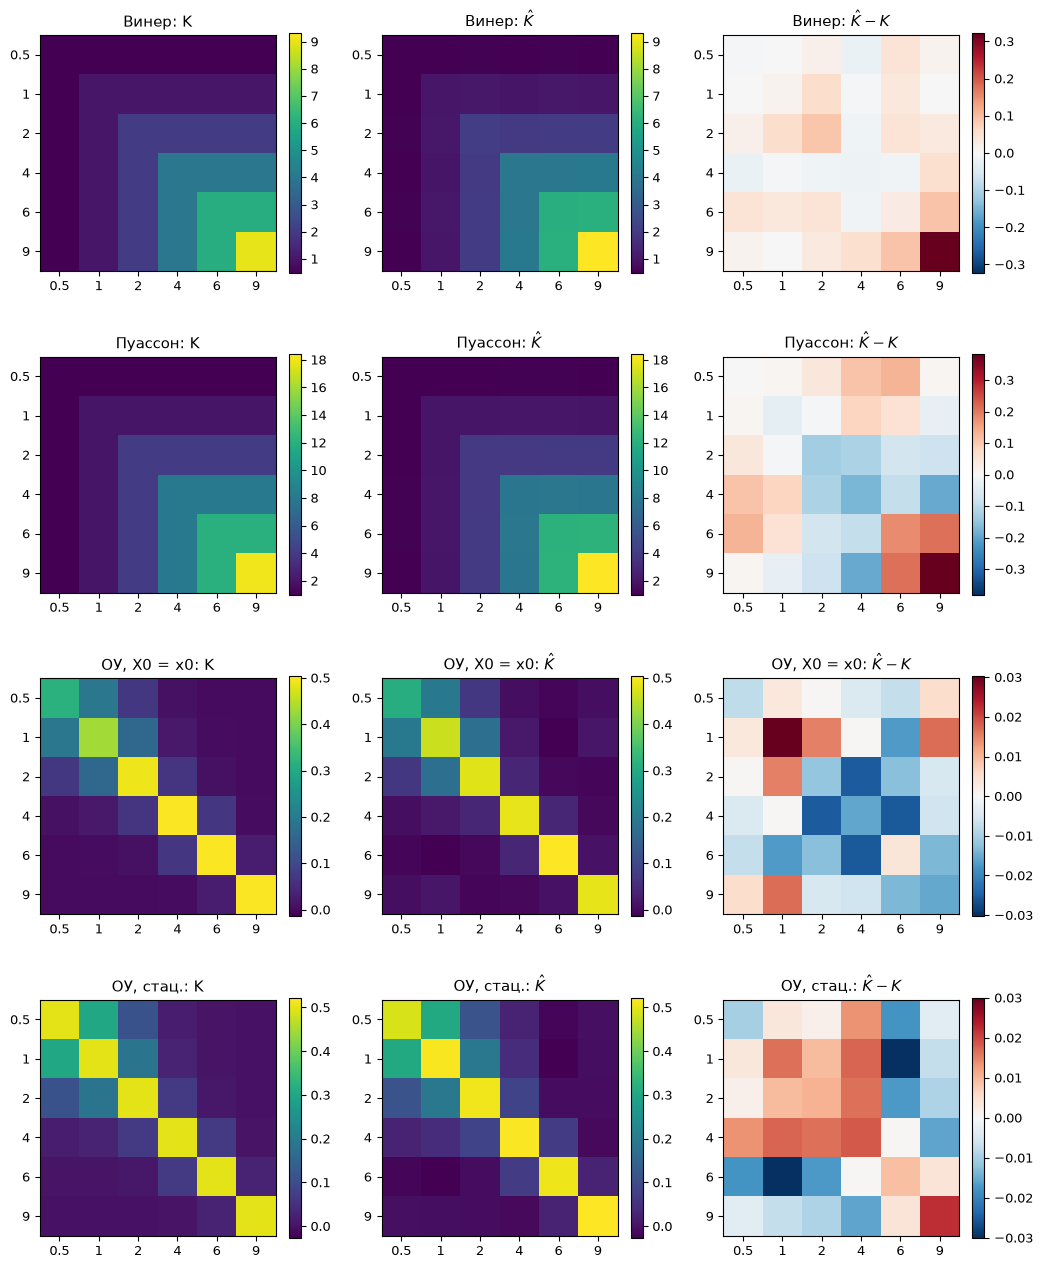

,‖K̂ − K‖F / ‖K‖F,max |K̂ − K|,max K
процесс,,,
Винер,0.0225,0.3229,9.0
Пуассон,0.0209,0.3811,18.0
"ОУ, X0 = x0",0.0691,0.0303,0.5
"ОУ, стац.",0.0624,0.0300,0.5


In [7]:
def sample_cov(V):
    Vc = V - V.mean(axis=0)
    return Vc.T @ Vc / (V.shape[0] - 1)


def time_index(t, times):
    idx = np.rint(np.asarray(times) / (t[1] - t[0])).astype(int)
    assert np.allclose(t[idx], times)
    return idx


def rel_frob(K_hat, K):
    return np.linalg.norm(K_hat - K) / np.linalg.norm(K)


labels = [f"{x:g}" for x in COV_TIMES]
fig, axes = plt.subplots(4, 3, figsize=(10.5, 13))
rows = []
for r, (name, (t, X)) in enumerate(ENS.items()):
    K = PROC[name]["cov"](COV_TIMES, COV_TIMES)
    K_hat = sample_cov(X[:, time_index(t, COV_TIMES)])
    lo, hi = min(K.min(), K_hat.min()), max(K.max(), K_hat.max())
    dmax = np.abs(K_hat - K).max()
    for c, (mat, title, kw) in enumerate(
        [
            (K, "K", dict(cmap="viridis", vmin=lo, vmax=hi)),
            (K_hat, "$\\hat K$", dict(cmap="viridis", vmin=lo, vmax=hi)),
            (K_hat - K, "$\\hat K - K$", dict(cmap="RdBu_r", vmin=-dmax, vmax=dmax)),
        ]
    ):
        ax = axes[r, c]
        im = ax.imshow(mat, **kw)
        ax.set_xticks(range(len(labels)), labels)
        ax.set_yticks(range(len(labels)), labels)
        ax.grid(False)
        ax.set_title(f"{name}: {title}")
        fig.colorbar(im, ax=ax, fraction=0.046)
    rows.append({"процесс": name, "‖K̂ − K‖F / ‖K‖F": rel_frob(K_hat, K), "max |K̂ − K|": dmax, "max K": K.max()})
fig.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("процесс")

**Интерпретация.** Тепловые карты $K$ и $\hat K$ визуально совпадают. У $W$ и $N$ видна «лестничная» структура $\min(t_i, t_j)$: элементы растут к правому нижнему углу, а строка $i$ постоянна правее диагонали. У ОУ матрица сосредоточена у диагонали и убывает как $e^{-\theta|t_i - t_j|}$. При фиксированном начале левый верхний угол меньше: в $t = 0.5$ дисперсия равна $0.5(1 - e^{-1}) = 0.32$, а не 0.5.

Относительная ошибка Фробениуса при $M = 2000$ равна 2.2% для $W$, 2.1% для $N$ и 6–7% для ОУ. Абсолютная ошибка у $W$ и $N$ максимальна в правом нижнем углу, где больше сами дисперсии, а знаки ошибок в соседних клетках согласованы: все элементы оцениваются по одним и тем же накопленным приращениям. У ОУ относительная ошибка выше по другой причине. Норма $K$ определяется в основном диагональю, а внедиагональные элементы почти нулевые, но оцениваются с той же по порядку ошибкой $\approx\sqrt{K_{ii}K_{jj}/M}$, и шум по 30 внедиагональным элементам складывается.

### 3.3 Зависимость ошибок от числа траекторий

**Вопрос.** Как ошибки оценивания ковариационной матрицы и дисперсии меняются с ростом $M$?

Для каждого $M$ из сетки 50–5000 ансамбль моделируется заново $20$ раз, по каждому повторению считаются относительная ошибка Фробениуса для $\hat K$ и $\max_{t \ge 0.5}|\hat v/v - 1|$; на графике — среднее по повторениям и полоса между 10% и 90% квантилями. Наклон прямой в двойном логарифмическом масштабе оценивается методом наименьших квадратов; для оценок вида выборочного среднего ожидается $M^{-1/2}$.

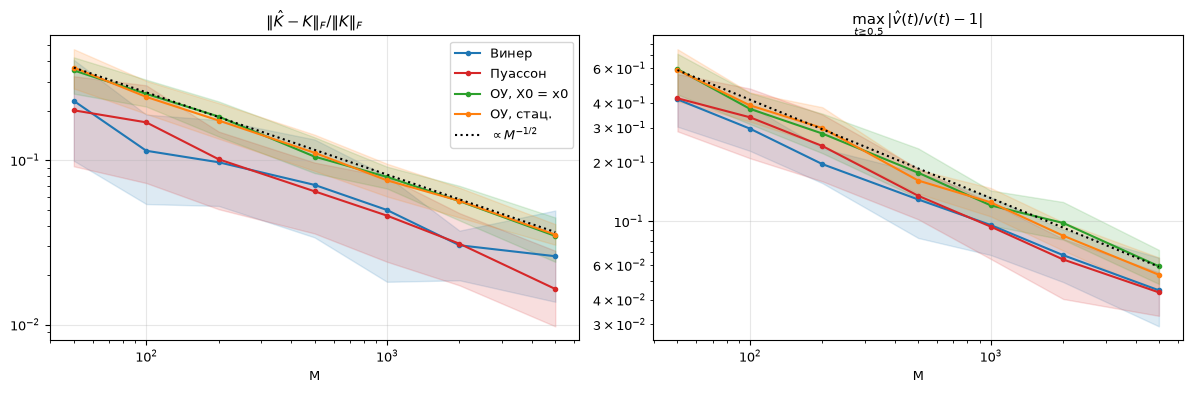

M,50,100,200,500,1000,2000,5000,наклон K,наклон v
процесс,,,,,,,,,
Винер,0.2295,0.1142,0.0972,0.0708,0.0498,0.0304,0.0261,-0.4569,-0.4841
"ОУ, X0 = x0",0.3515,0.2532,0.1842,0.1052,0.0792,0.0564,0.0346,-0.5049,-0.4872
"ОУ, стац.",0.3657,0.2427,0.1743,0.1110,0.0755,0.0566,0.0353,-0.5024,-0.5191
Пуассон,0.2011,0.1699,0.1013,0.0647,0.0460,0.0311,0.0165,-0.5467,-0.5180


In [8]:
recs = []
for i, (name, p) in enumerate(PROC.items()):
    K = p["cov"](COV_TIMES, COV_TIMES)
    rng = rng_for(3, i)
    for Mi in M_GRID:
        for _ in range(N_REP):
            t, X = p["sim"](T, dt, Mi, rng)
            late = t >= 0.5
            v = theory_var(p, t)[late]
            recs.append(
                {
                    "процесс": name,
                    "M": Mi,
                    "ошибка K": rel_frob(sample_cov(X[:, time_index(t, COV_TIMES)]), K),
                    "ошибка v": np.abs(X[:, late].var(axis=0, ddof=1) / v - 1).max(),
                }
            )
ERR_M = pd.DataFrame(recs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
slopes = {}
for ax, col in zip(axes, ["ошибка K", "ошибка v"]):
    for name in PROC:
        g = ERR_M[ERR_M["процесс"] == name].groupby("M")[col]
        mean, q1, q9 = g.mean(), g.quantile(0.1), g.quantile(0.9)
        ax.fill_between(mean.index, q1, q9, color=COLORS[name], alpha=0.15)
        ax.plot(mean.index, mean, "o-", color=COLORS[name], ms=3, label=name)
        slopes[(name, col)] = np.polyfit(np.log(mean.index), np.log(mean.values), 1)[0]
    ref = mean.iloc[0] * np.sqrt(M_GRID[0] / np.array(M_GRID))
    ax.plot(M_GRID, ref, "k:", label="$\\propto M^{-1/2}$")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("M")
axes[0].set_title("$\\|\\hat K - K\\|_F / \\|K\\|_F$")
axes[1].set_title("$\\max_{t\\geq 0.5} |\\hat v(t)/v(t) - 1|$")
axes[0].legend()
fig.tight_layout()
plt.show()

table = ERR_M.groupby(["процесс", "M"])["ошибка K"].mean().unstack("M")
table["наклон K"] = [slopes[(n, "ошибка K")] for n in table.index]
table["наклон v"] = [slopes[(n, "ошибка v")] for n in table.index]
table

**Интерпретация.** Обе ошибки убывают степенным образом: наклоны в логарифмическом масштабе от $-0.46$ до $-0.55$ для $\hat K$ и от $-0.48$ до $-0.52$ для дисперсии, т. е. закон $M^{-1/2}$. При росте $M$ от 50 до 5000 (в 100 раз) ошибка $\hat K$ уменьшается примерно в 10 раз: у $W$ с 0.23 до 0.026, у ОУ с 0.35–0.37 до 0.035. Полоса между квантилями повторений сужается так же. Каждое уменьшение ошибки вдвое требует вчетверо больше траекторий. Порядок процессов по точности сохраняется при всех $M$ ($W$ и $N$ точнее ОУ, причины указаны в 3.2), а значения при $M = 2000$ совпадают с результатом одного прогона в 3.2.